# Eksploracja danych — brakujące wartości

**Cel zajęć:** nauczyć się *znajdować* braki (także te ukryte), *diagnozować*, czy są przypadkowe, i *świadomie wybierać*, czy je usunąć, czy uzupełnić.

**Plan:**
1. Rozgrzewka na zbiorze **Titanic** — te same kroki co na wykładzie.
2. Zadanie główne: **oferty mieszkań** (`nieruchomosci.csv`) — prawdziwy bałagan.

**Zadania:** 🟢 podstawowe (obowiązkowe), 🔵 dla ambitnych.

**Jak pracować:** w Colabie wybierz *Plik → Zapisz kopię na Dysku*, wgraj plik `nieruchomosci.csv` (ikona folderu po lewej → *Prześlij*), rozwiąż zadania w miejscach `# TODO`, a gotowy notatnik umieść w swoim repozytorium na GitHubie.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({"figure.figsize": (7, 4), "font.size": 11})

URL_TITANIC = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
titanic = pd.read_csv("titanic.csv") if Path("titanic.csv").exists() else pd.read_csv(URL_TITANIC)

if not Path("nieruchomosci.csv").exists():
    print("⚠️ Wgraj plik nieruchomosci.csv do bieżącego katalogu (w Colabie: ikona folderu → Prześlij).")

print(titanic.shape)
titanic.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


---
# Część 1. Rozgrzewka: Titanic

| kolumna | znaczenie |
|---|---|
| `Survived` | czy pasażer przeżył (1 = tak) |
| `Pclass` | klasa biletu (1, 2, 3) |
| `Sex`, `Age` | płeć, wiek |
| `SibSp`, `Parch` | liczba rodzeństwa/małżonków oraz rodziców/dzieci na pokładzie |
| `Fare` | cena biletu (£) |
| `Cabin` | numer kabiny |
| `Embarked` | port zaokrętowania: C — Cherbourg, Q — Queenstown, S — Southampton |

### 🟢 Zadanie 1: ile jest braków?

1. Policz liczbę i odsetek braków w każdej kolumnie. Pokaż tylko kolumny, w których braki występują, posortowane malejąco.
2. Narysuj poziomy wykres słupkowy odsetka braków (`.plot.barh()`), z opisem osi.

Cabin       687
Age         177
Embarked      2
dtype: int64


Cabin       77.104377
Age         19.865320
Embarked     0.224467
dtype: float64


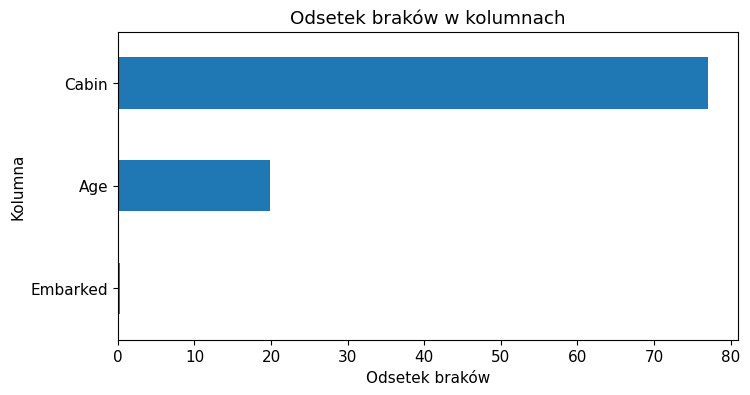

In [2]:
# TODO

liczba_brakow = titanic.isna().sum() # tabela z komulmna liczba braków
maska_braki = liczba_brakow[liczba_brakow>0]
maska_braki = maska_braki.sort_values(ascending=False) # wszystko więc nie wyznaczam kolumny
print(maska_braki)

# sprawdzenie
# liczbaT = titanic.isna().sum() # > 0 # maska
# print(liczbaT)
print("\n") # indeks to nazwa kolumny, gdzie mam braki
# mean, bo proporcja, część całości, daje ułamek, bo liczy średnią z 0 i 1 na x, czyli ile jest % braków
odsetek_brakow = titanic.isna().mean()[maska_braki.index] * 100
odsetek_brakow = odsetek_brakow.sort_values(ascending=False)
print(odsetek_brakow)
# print(titanic.isna().mean()*100)

fig, ax = plt.subplots(figsize=(8, 4))
odsetek_brakow.plot.barh(maska_braki.index, odsetek_brakow)
ax.set_xlabel("Odsetek braków")
ax.set_ylabel("Kolumna")
ax.set_title("Odsetek braków w kolumnach")
ax.invert_yaxis()
plt.show()

### 🟢 Zadanie 2: mapa braków

Narysuj mapę braków (`sns.heatmap(titanic.isna(), cbar=False)`) dla kolumn `Age`, `Cabin`, `Embarked` — najpierw z wierszami w oryginalnej kolejności, a potem **posortowanymi według klasy** (`Pclass`). Dwa wykresy obok siebie.

Co widać na drugim wykresie, czego nie było widać na pierwszym?

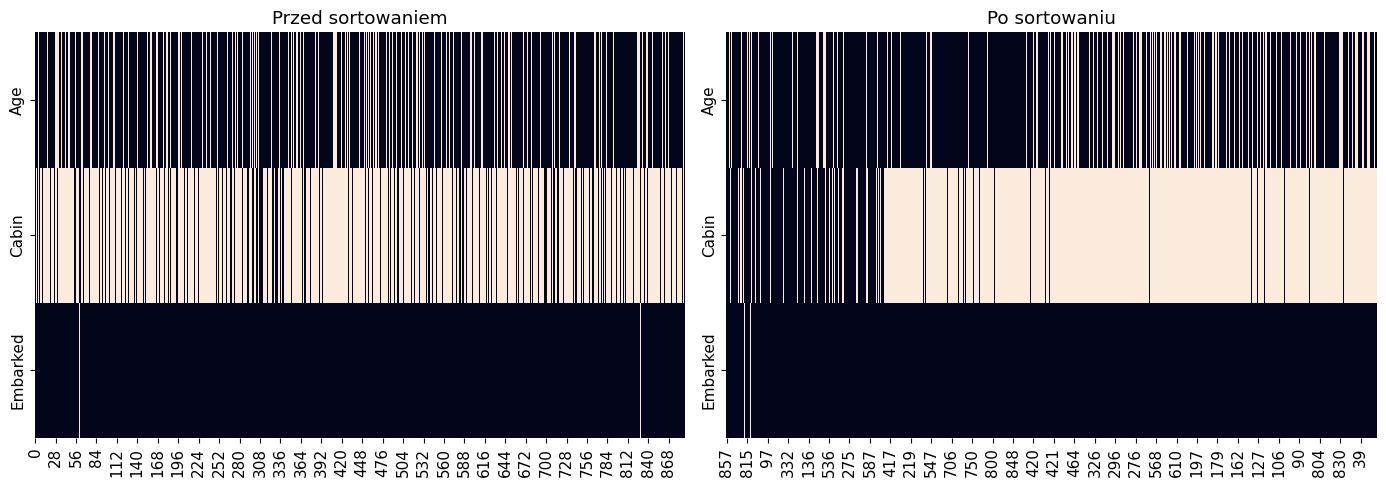

In [3]:
kolumny = ["Age", "Cabin", "Embarked"]

# TODO
braki = titanic[kolumny].isna()
kolejnosc = titanic.sort_values("Pclass").index

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(braki.T, cbar=False, ax=axes[0])
axes[0].set_title("Przed sortowaniem")
sns.heatmap(braki.loc[kolejnosc].T, cbar=False, ax=axes[1])
axes[1].set_title("Po sortowaniu")
plt.tight_layout()
plt.show()

*Twoja odpowiedź:* …
* Widzimy podział na klasy pasażerskie
* Wynika z nich, że mamy o wiele więcej utraconych danych w niższych klasach
* Najwięcej braków mamy w przypadku numerów kabin dla 3 klasy pasażerskiej

### 🟢 Zadanie 3: czy braki wieku są losowe?

1. Utwórz serię `brak_wieku = titanic["Age"].isna()`.
2. Policz odsetek braków wieku w każdej klasie i osobno dla każdej płci.
3. Porównaj odsetek ocalałych wśród osób ze znanym wiekiem i bez wieku.
4. Narysuj wyniki z punktów 2 i 3 na dwóch wykresach słupkowych.
5. Czy braki wieku to MCAR? Co by się stało z odsetkiem ocalałych, gdybyśmy usunęli wiersze bez wieku?

Pclass
1    13.888889
2     5.978261
3    27.698574
Name: Age, dtype: float64 

Sex
female    16.878981
male      21.490468
Name: Age, dtype: float64 

brak_wieku
False    40.616246
True     29.378531
Name: Survived, dtype: float64 



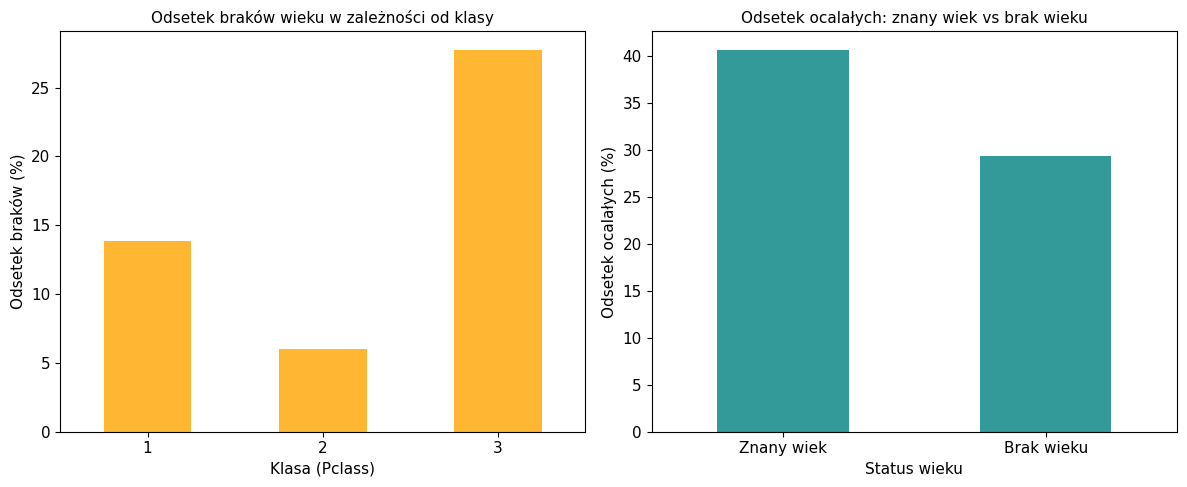

In [4]:
brak_wieku = titanic["Age"].isna()
# TODO

# grupuje według b z tablicy a
odsetek_klasa = brak_wieku.groupby(titanic["Pclass"]).mean() * 100
print(odsetek_klasa, "\n")
odsetek_plec = brak_wieku.groupby(titanic["Sex"]).mean() * 100
print(odsetek_plec, "\n")

titanic_dla_wieku = titanic.copy()
titanic_dla_wieku["brak_wieku"] = brak_wieku
# dzielimy ze względu na wiek i patrzymy na przeżycie
ocalali_wedlug_wieku = titanic_dla_wieku.groupby("brak_wieku")["Survived"].mean() * 100
print(ocalali_wedlug_wieku, "\n")

# albo od razu zamiast tworzyć nową tabelę by segregować po nowej kolumnie
# ocalali_wedlug_wieku = titanic.groupby(titanic["Age"].isna())["Survived"].mean() * 100



fig, axes = plt.subplots(1, 2, figsize=(12, 5))
odsetek_klasa.plot(kind="bar", ax=axes[0], color="orange", alpha=0.8)
axes[0].set_title("Odsetek braków wieku w zależności od klasy", fontsize=11)
axes[0].set_xlabel("Klasa (Pclass)")
axes[0].set_ylabel("Odsetek braków (%)")
axes[0].tick_params(axis="x", rotation=0)
ocalali_wedlug_wieku.index = ["Znany wiek", "Brak wieku"]
ocalali_wedlug_wieku.plot(kind="bar", ax=axes[1], color="teal", alpha=0.8)
axes[1].set_title( "Odsetek ocalałych: znany wiek vs brak wieku", fontsize=11 )
axes[1].set_xlabel("Status wieku")
axes[1].set_ylabel("Odsetek ocalałych (%)")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()



*Twoja odpowiedź:* …
* Nie są całowicie losowe, ponieważ klasy nie mają podobnych wartości
* Gdybyśmy je usunęli stracilibyśmy ważne dane i statystyki, ponieważ bardzo by to dotknęło psażerów klasy 3

### 🟢 Zadanie 4: ile kosztuje usuwanie?

Dla czterech wariantów — bez zmian, `dropna(subset=["Embarked"])`, `dropna(subset=["Age"])`, `dropna()` — zbuduj tabelę z kolumnami:
- liczba wierszy,
- odsetek ocalałych,
- odsetek pasażerów 1. klasy.

Który wariant najbardziej zniekształca dane i dlaczego?

In [5]:
warianty = { # wiersze
    "bez zmian": titanic,
    # TODO: pozostałe warianty
    "e": titanic.dropna(subset=["Embarked"]),
    "a": titanic.dropna(subset=["Age"]),
    "d": titanic.dropna()
}

# TODO: tabela
# puste, niepołączone ze sobą listy, kolumny
liczba_wierszy = []
odsetek_ocalali = []
odsetek_klasa1 = []

for nazwa, dane in warianty.items(): # z słownika biorę wartości do kolumn
    liczba_wierszy.append(dane.shape[0])
    odsetek_ocalali.append((dane["Survived"] == 1).mean() * 100)
    odsetek_klasa1.append((dane["Pclass"] == 1).mean() * 100)

wyniki = {
    "Liczba wierszy": liczba_wierszy,
    "Odsetek ocalałych": odsetek_ocalali,
    "Odsetek pasażerów 1. klasy": odsetek_klasa1
}

porownanie = pd.DataFrame(wyniki,index=warianty.keys())
print(porownanie)

           Liczba wierszy  Odsetek ocalałych  Odsetek pasażerów 1. klasy
bez zmian             891          38.383838                   24.242424
e                     889          38.245219                   24.071991
a                     714          40.616246                   26.050420
d                     183          67.213115                   86.338798


*Twoja odpowiedź:* …
* Wariant usuwający wszystkie braki najbardziej zniekształca dane, ponieważ usuwa 708 wierszy, co całkowicie niszczy statystyki, w porównaniu bez zmian odsetek ocalałych wzrósł do 67.21%, a odsetek pasażerów 1 klasy to 86.34, co nie ma sensu, ponieważ 1 klasa jest najdroższa, więc większość pasażerów nie może w niej mieć biletów

### 🟢 Zadanie 5: uzupełnianie wieku

1. **Najpierw** dodaj kolumnę-flagę `Age_brak`.
2. Utwórz dwie wersje kolumny wieku:
   - `wiek_srednia` — braki uzupełnione średnią,
   - `wiek_grupy` — braki uzupełnione medianą w grupach (klasa × płeć); wskazówka: `groupby(...)["Age"].transform("median")`.
3. Narysuj trzy histogramy obok siebie (te same przedziały, `bins=np.arange(0, 82, 2)`): znane wartości, `wiek_srednia`, `wiek_grupy`.
4. Porównaj odchylenia standardowe. Która metoda bardziej zniekształca rozkład?

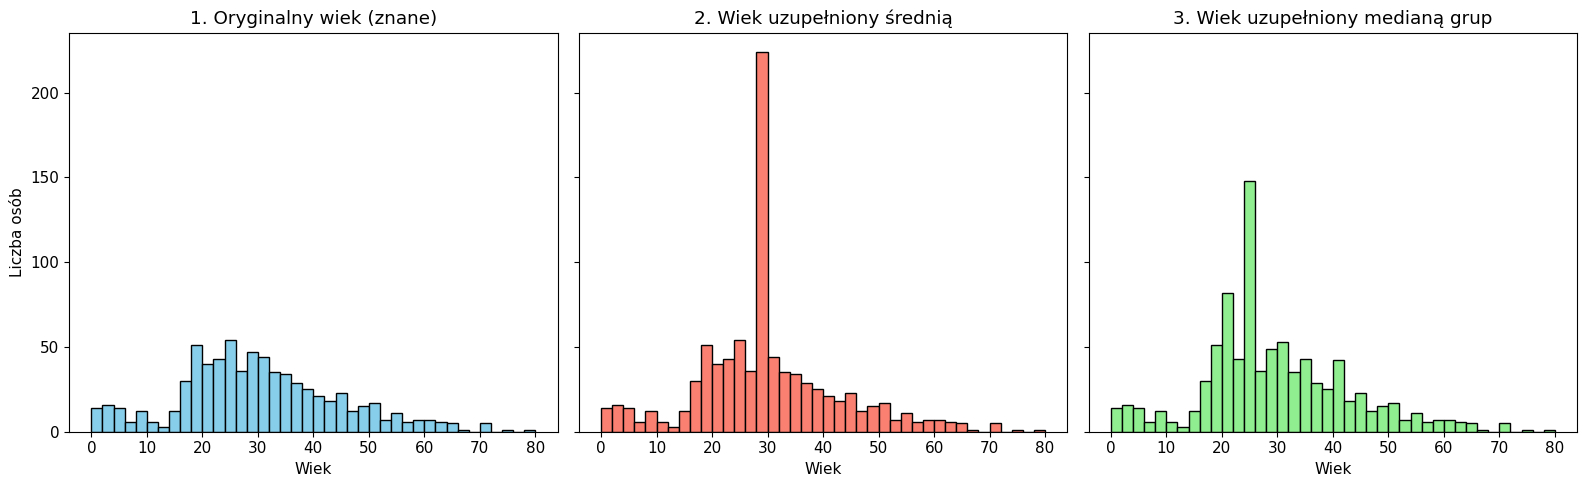

Oryginalny wiek: 14.526497332334044
Wiek uzupełniony średnią: 13.002015226002884
Wiek uzupełniony grupami: 13.304424074688153


In [6]:
# TODO
titanic["Age_brak"] = titanic["Age"].isna()
# fill, wypełnij, na -> nan -> braki średnim wiekiem
titanic["wiek_srednia"] = titanic["Age"].fillna(titanic["Age"].mean())
#liczymy medianę wieku dla każdej grupy k1 k2 k3 m1 m2 m3
# transform rozciągam zwężenie grupowania spowrotem do całości tabeli
mediany_grup = titanic.groupby(["Pclass", "Sex"])["Age"].transform("median")
titanic["wiek_grupy"] = titanic["Age"].fillna(mediany_grup)
# print(titanic)

bins = np.arange(0, 82, 2)
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

axes[0].hist(titanic["Age"].dropna(), bins=bins, color="skyblue", edgecolor="black")
axes[0].set_title("1. Oryginalny wiek (znane)")
axes[0].set_xlabel("Wiek")
axes[0].set_ylabel("Liczba osób")

axes[1].hist(titanic["wiek_srednia"], bins=bins, color="salmon", edgecolor="black")
axes[1].set_title("2. Wiek uzupełniony średnią")
axes[1].set_xlabel("Wiek")

axes[2].hist(titanic["wiek_grupy"], bins=bins, color="lightgreen", edgecolor="black")
axes[2].set_title("3. Wiek uzupełniony medianą grup")
axes[2].set_xlabel("Wiek")

plt.tight_layout()
plt.show()

print("Oryginalny wiek:", titanic["Age"].std())
print("Wiek uzupełniony średnią:", titanic["wiek_srednia"].std())
print("Wiek uzupełniony grupami:", titanic["wiek_grupy"].std())


*Twoja odpowiedź:* …
* Najbardziej zniekształca rozkład metoda ze średnią, ponieważ wszystkie puste miejsca dostają tą samą wartość
* Zaburza to rozkład, ponieważ teraz mamy skupienie w jednym miejscu, obniża to odchylenie standardowe

### 🔵 Zadanie 6 (dla ambitnych): imputacja modelem

Uzupełnij wiek za pomocą `IterativeImputer` z biblioteki scikit-learn, wykorzystując kolumny `Pclass`, `SibSp`, `Parch`, `Fare` oraz płeć zakodowaną jako 0/1. Porównaj histogram i odchylenie standardowe z wynikami zadania 5.

```python
from sklearn.experimental import enable_iterative_imputer  # wymagane!
from sklearn.impute import IterativeImputer
```

0      22.000000
1      38.000000
2      26.000000
3      35.000000
4      35.000000
         ...    
886    27.000000
887    19.000000
888    19.666103
889    26.000000
890    32.000000
Name: wiek_iterative, Length: 891, dtype: float64


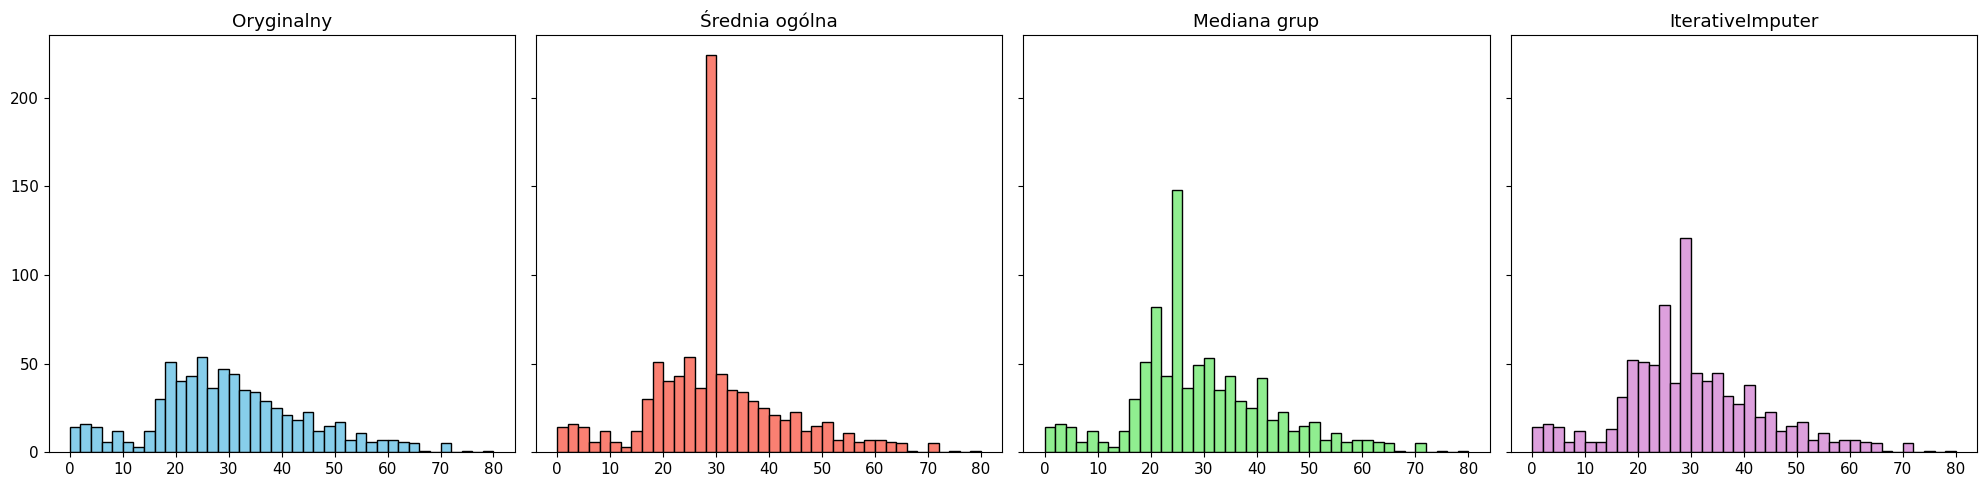

Oryginalne (znane): 14.526497332334044
Wiek ze średnią: 13.002015226002884
Wiek z medianą grup: 13.304424074688153
Wiek z IterativeImputer: 13.63703733851967


In [7]:
# TODO
from sklearn.experimental import enable_iterative_imputer  # wymagane!
from sklearn.impute import IterativeImputer

titanic["Sex_num"] = titanic["Sex"].map({"male": 0, "female": 1})

kolumny_modelu = ["Pclass", "Sex_num", "SibSp", "Parch", "Fare", "Age"]
dane_do_modelu = titanic[kolumny_modelu]

imputer = IterativeImputer(random_state=42)
dane_po_imputacji = imputer.fit_transform(dane_do_modelu)

# wybieram przez indeks, a nie nazwę, bo fit_transform() usuwa nazwy kolumn i zwraca czystą tablicę NumPy
titanic["wiek_iterative"] = dane_po_imputacji[:, 5]
print(titanic["wiek_iterative"])

bins = np.arange(0, 82, 2)
fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=True)

axes[0].hist(titanic["Age"].dropna(), bins=bins, color="skyblue", edgecolor="black")
axes[0].set_title("Oryginalny")

axes[1].hist(titanic["wiek_srednia"], bins=bins, color="salmon", edgecolor="black")
axes[1].set_title("Średnia ogólna")

axes[2].hist(titanic["wiek_grupy"], bins=bins, color="lightgreen", edgecolor="black")
axes[2].set_title("Mediana grup")

axes[3].hist(titanic["wiek_iterative"], bins=bins, color="plum", edgecolor="black")
axes[3].set_title("IterativeImputer")

plt.tight_layout()
plt.show()

print("Oryginalne (znane):", titanic["Age"].std())
print("Wiek ze średnią:", titanic["wiek_srednia"].std())
print("Wiek z medianą grup:", titanic["wiek_grupy"].std())
print("Wiek z IterativeImputer:", titanic["wiek_iterative"].std())



---
# Część 2. Zadanie główne: oferty mieszkań

**Dane:** plik `nieruchomosci.csv` — 45 ofert sprzedaży mieszkań w pięciu miastach.

| kolumna | znaczenie |
|---|---|
| `powierzchnia` | powierzchnia mieszkania [m²] |
| `rok_budowy` | rok budowy budynku |
| `pietro`, `liczba_pieter` | piętro mieszkania (0 = parter) i liczba pięter budynku |
| `parking`, `balkon` | Tak / Nie |
| `stan` | stan mieszkania |
| `cena_m2`, `cena_total` | cena za m² i cena całkowita [zł] |

Plik przygotował ktoś, kto różne braki zapisywał na różne sposoby. Twoim zadaniem jest je znaleźć i rozsądnie obsłużyć.

### 🟢 Zadanie 7: pierwszy rzut oka

1. Wczytaj plik bez żadnych dodatkowych parametrów i sprawdź typy kolumn (`dtypes`).
2. Policz braki (`isna().sum()`). Ile braków widzi pandas?
3. Dlaczego kolumna `powierzchnia` nie jest liczbowa, choć zawiera powierzchnię w m²?

In [8]:
mieszkania = pd.read_csv("nieruchomosci.csv")

# TODO
print(mieszkania.dtypes)
print("\n")
print(mieszkania.isna().sum())
print("\n")
print(mieszkania.isna().sum().sum())


id                int64
miasto           object
dzielnica        object
powierzchnia     object
liczba_pokoi      int64
rok_budowy       object
pietro           object
liczba_pieter     int64
parking          object
balkon           object
stan             object
cena_m2           int64
cena_total        int64
dtype: object


id               0
miasto           0
dzielnica        0
powierzchnia     4
liczba_pokoi     0
rok_budowy       4
pietro           0
liczba_pieter    0
parking          0
balkon           0
stan             0
cena_m2          0
cena_total       0
dtype: int64


8


*Twoja odpowiedź:* …

* W całości jest 8 braków
* Jest obiektem, ponieważ ma tam też stringi jak "brak", więc dla bezpieczeństwa python ustawia całą kolumne jako object



### 🟢 Zadanie 8: braki „w przebraniu”

1. Dla każdej kolumny tekstowej i każdej kolumny liczbowej obejrzyj występujące wartości (`value_counts(dropna=False)` albo `unique()`). Wypisz wszystkie wartości, które oznaczają brak.
2. **Pułapka:** w kolumnach `powierzchnia` i `pietro` występuje `0`. Czy w obu przypadkach to brak danych?
3. Wczytaj plik ponownie z parametrem `na_values` podanym jako **słownik** (kolumna → lista wartości), tak aby każda kolumna miała tylko „swoje” oznaczenia braków.
4. Sprawdź typy kolumn i policz braki jeszcze raz.

In [9]:
# TODO 1
for k in mieszkania.columns:
        # print(mieszkania[k].value_counts(dropna=False),"\n")
        print(f"{k}:", mieszkania[k].unique(),"\n")



id: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45] 

miasto: ['Warszawa' 'Kraków' 'Wrocław' 'Poznań' 'Gdańsk'] 

dzielnica: ['Mokotów' 'Krowodrza' 'Krzyki' 'Grunwald' 'Wrzeszcz' 'Śródmieście'
 'Podgórze' 'Stare Miasto' 'Jeżyce' 'Oliwa' 'Żoliborz' 'Kazimierz'
 'Psie Pole' 'Rataje' 'Siedlce' 'Praga' 'Nowa Huta' 'Fabryczna' 'Wilda'
 'Przymorze' 'Ochota' 'Bronowice' 'Centrum' 'Ursynów' 'Dębniki' 'Zaspa'
 'Wilanów' 'Łagiewniki' 'Biskupin' 'Sołacz' 'Chełm' 'Bielany' 'Ruczaj'
 'Gaj' 'Główna' 'Morena' 'Targówek' 'Mistrzejowice' 'Ołbin' 'Piątkowo'
 'Suchanino'] 

powierzchnia: ['65' '48' '72' '55' '80' nan '60' '45' '70' '90' '58' '52' '68' '0' '75'
 '62' '50' 'brak' '66' '85' '54' '95' '56' '42' '78' '88' '64' '51' '69'
 '46' '82' '76'] 

liczba_pokoi: [3 2 4 1 5] 

rok_budowy: ['2015' nan '2010' '2018' '1998' '2020' '2005' '2019' 'brak' '2001' '2016'
 '1995' '2012' '2017' '2014' '2008' '2011' '1999' '20

*Twoja odpowiedź:* …
* Wartości oznaczające braki to: 0, brak i nan dla powierzchni, nan i brak dla roku budowy, brak i -999 dla numeru piętra, ? dla parkingu, ? dla balkonu, -1 i -999 dla cena_m2
* Nie, ponieważ 0 dla piętra może oznaczać parter, pientro 0, a powierzchnia nie może być równa 0, bo wtedy nie ma mieszkania
*
* Nowe typy kolumn poprawnie odpowiadają ich zawartości np. powierzchnia to teraz float64
* Mamy 29 błędów, co odpowiada ilości zamienionych oznaczeń

In [10]:
braki_slownik = { # nan nie musimy wpisywać do słownika, bo ono już poprawnie oznacza brak
    "powierzchnia": ["brak", "0"],
    "rok_budowy": ["brak"],
    "pietro": [ "brak", "-999"],
    "parking": ["?"],
    "balkon": ["?"],
    "cena_m2": ["-1", "-999"]
}

mieszkania = pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)

# TODO: typy i liczba braków
print(mieszkania.dtypes)
print("\n")
print(mieszkania.isna().sum())
print("\n")
print(mieszkania.isna().sum().sum())


id                 int64
miasto            object
dzielnica         object
powierzchnia     float64
liczba_pokoi       int64
rok_budowy       float64
pietro           float64
liczba_pieter      int64
parking           object
balkon            object
stan              object
cena_m2          float64
cena_total         int64
dtype: object


id               0
miasto           0
dzielnica        0
powierzchnia     9
liczba_pokoi     0
rok_budowy       7
pietro           3
liczba_pieter    0
parking          5
balkon           3
stan             0
cena_m2          2
cena_total       0
dtype: int64


29


### 🟢 Zadanie 9: dziwna kategoria

Obejrzyj wartości w kolumnie `stan`. Jedna z nich nie pasuje do pozostałych. Co mogła oznaczać i jak ją poprawić? Zaproponuj i zastosuj rozwiązanie (uzasadnij je).

In [11]:
# TODO
# według tłumacza google "很好" oznacza bardzo dobry, więc moglibyśmy poprawić tą wartość na "Bardzo dobry"
mieszkania["stan"] = mieszkania["stan"].replace("很好", "Bardzo dobry")

### 🟢 Zadanie 10: mapa braków

1. Narysuj odsetek braków w kolumnach (wykres słupkowy) i mapę braków.
2. Czy braki w różnych kolumnach występują w tych samych wierszach? (Wskazówka: `mieszkania.isna().corr()` dla kolumn z brakami.)

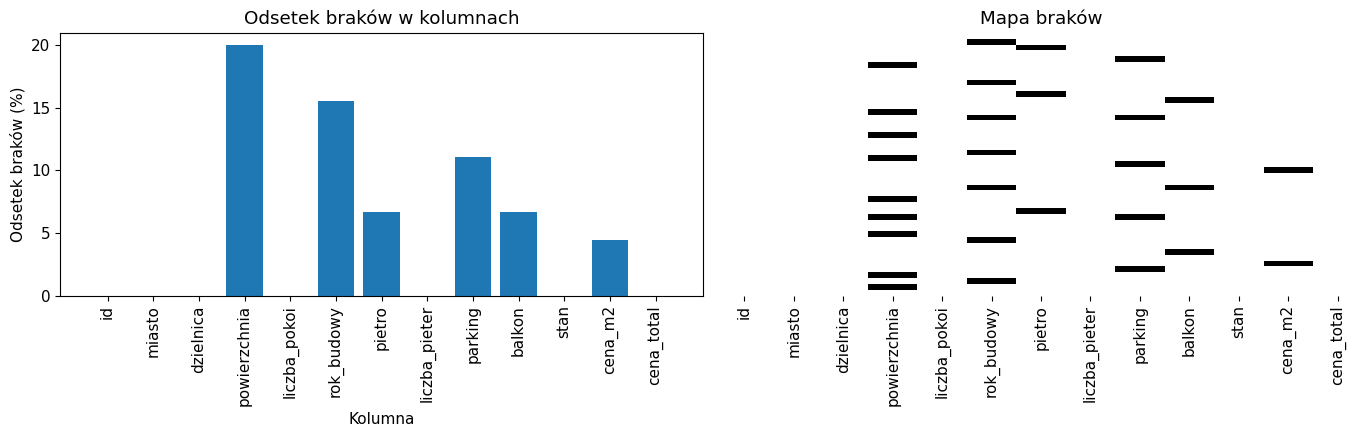

               id  miasto  dzielnica  powierzchnia  liczba_pokoi  rok_budowy  \
id            NaN     NaN        NaN           NaN           NaN         NaN   
miasto        NaN     NaN        NaN           NaN           NaN         NaN   
dzielnica     NaN     NaN        NaN           NaN           NaN         NaN   
powierzchnia  NaN     NaN        NaN  1.000000e+00           NaN   -0.214599   
liczba_pokoi  NaN     NaN        NaN           NaN           NaN         NaN   
rok_budowy    NaN     NaN        NaN -2.145988e-01           NaN    1.000000   
pietro        NaN     NaN        NaN -1.336306e-01           NaN   -0.114708   
liczba_pieter NaN     NaN        NaN           NaN           NaN         NaN   
parking       NaN     NaN        NaN -4.170558e-17           NaN    0.043355   
balkon        NaN     NaN        NaN -1.336306e-01           NaN    0.131095   
stan          NaN     NaN        NaN           NaN           NaN         NaN   
cena_m2       NaN     NaN        NaN -1.

In [12]:
# TODO

liczba_brakow = mieszkania.isna().sum()
odsetek_brakow = mieszkania.isna().mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].bar(liczba_brakow.index, odsetek_brakow)
axes[0].set_title("Odsetek braków w kolumnach")
axes[0].set_xlabel("Kolumna")
axes[0].set_ylabel("Odsetek braków (%)")
axes[0].tick_params(axis="x", rotation=90)

sns.heatmap(mieszkania.isna(), cbar=False, ax=axes[1], yticklabels=False, cmap="binary")
axes[1].set_title("Mapa braków")
plt.tight_layout()
plt.show()

print(mieszkania.isna().corr())





*Twoja odpowiedź:* …
* Braki nie są od siebie zależne, są losowe, jeden zapis nie ma wielu pustych kolumn
* Widzimy to z wykresu, nie ma ciągłych czarnych linii braków
* Oraz z współczynnika korelacji, ponieważ w żadnej kolumnie nie występuje współczynik bliski 1 (brak w kolumnie a oznacza brak w kolumnie b) lub -1 (wartość w kolumnie a oznacza wartość w kolumnie b)

### 🟢 Zadanie 11: odtwórz, zamiast zgadywać

Sprawdź, czy dla wierszy bez braków zachodzi zależność `cena_total = powierzchnia × cena_m2`. Jeśli tak — wykorzystaj ją, żeby **odtworzyć** brakujące wartości w kolumnach `powierzchnia` i `cena_m2`. Ile braków udało się w ten sposób usunąć?

To jest „ręczne uzupełnianie” z wykładu: znamy prawdziwą wartość, więc nie musimy jej szacować.

In [13]:
# TODO
wiersze_bez_brakow = mieszkania[
    mieszkania["powierzchnia"].notna() & mieszkania["cena_m2"].notna()]

roznica = abs(
    wiersze_bez_brakow["cena_total"]
    - (wiersze_bez_brakow["powierzchnia"] * wiersze_bez_brakow["cena_m2"]))

print(roznica.max()) # największa różnica pokarze nam najgorszą zależność, tu 0 czyli jest zależność

ile_brakow_powierzchni = mieszkania["powierzchnia"].isna().sum()
ile_brakow_ceny = mieszkania["cena_m2"].isna().sum()
print("Ile mamy braków powierzchni:", ile_brakow_powierzchni, "Ile mamy braków ceny za m2:", ile_brakow_ceny)

maska_powierzchni = (
    mieszkania["powierzchnia"].isna()
    & mieszkania["cena_total"].notna()
    & mieszkania["cena_m2"].notna())

# wybieram z tabeli (mieszkania) wiersze spełniające warunek (maska_powierzchni) w kolumnie (powierzchnia)
mieszkania.loc[maska_powierzchni, "powierzchnia"] = (
    mieszkania.loc[maska_powierzchni, "cena_total"]
    / mieszkania.loc[maska_powierzchni, "cena_m2"])


maska_cena = (
    mieszkania["cena_m2"].isna()
    & mieszkania["cena_total"].notna()
    & mieszkania["powierzchnia"].notna())

mieszkania.loc[maska_cena, "cena_m2"] = (
    mieszkania.loc[maska_cena, "cena_total"]
    / mieszkania.loc[maska_cena, "powierzchnia"])


odtworzona_powierzchnia = ile_brakow_powierzchni - mieszkania["powierzchnia"].isna().sum()
odtworzona_cena = ile_brakow_ceny - mieszkania["cena_m2"].isna().sum()
print("Sprawdzenie czy faktycznie usunięto wszystkie braki", "Ile usunięto braków powierzchni:", odtworzona_powierzchnia, "Ile usunięto braków ceny za m2:", odtworzona_cena)



0.0
Ile mamy braków powierzchni: 9 Ile mamy braków ceny za m2: 2
Sprawdzenie czy faktycznie usunięto wszystkie braki Ile usunięto braków powierzchni: 9 Ile usunięto braków ceny za m2: 2


### 🟢 Zadanie 12: pozostałe braki

Dla każdej z kolumn `rok_budowy`, `pietro`, `parking`, `balkon`:
1. **Najpierw** dodaj kolumnę-flagę braku (np. `rok_budowy_brak`).
2. Zdecyduj, co zrobić z brakami, i zaimplementuj decyzję. Do rozważenia:
   - `rok_budowy` — mediana całościowa czy mediana w grupach? Jakie grupy mają sens: `miasto` czy `stan`? Policz mediany w obu podziałach, zanim wybierzesz.
   - `pietro` — są tylko 3 braki; mediana, a może coś mądrzejszego (np. środkowe piętro budynku: `liczba_pieter // 2`)?
   - `parking`, `balkon` — dominanta czy osobna kategoria `"nieznane"`? Co się stanie z odsetkiem mieszkań z parkingiem w każdym z tych wariantów?
3. Sprawdź, że w zbiorze nie ma już braków.

In [14]:
# TODO
# rok_budowy_brak = mieszkania["rok_budowy"].isna() flaga
mieszkania["rok_budowy_brak"] = mieszkania["rok_budowy"].isna() # kolumnwa flaga
mieszkania["pietro_brak"] = mieszkania["pietro"].isna()
mieszkania["parking_brak"] = mieszkania["parking"].isna()
mieszkania["balkon_brak"] = mieszkania["balkon"].isna()

print("Liczba braków w parkingu:", mieszkania["parking_brak"].sum())
print("Liczba braków w balkonie:", mieszkania["balkon_brak"].sum())

rok_budowy_mediana_calosciowa = mieszkania["rok_budowy"].median()
rok_budowy_mediana_miasto = mieszkania.groupby("miasto")["rok_budowy"].median()
rok_budowy_mediana_stan = mieszkania.groupby("stan")["rok_budowy"].median()
baza_do_testow = mieszkania.copy()
# mam Miasto miasto, bo pandas wypisuje nagłówek grupowania
print("Rok budowy - mediany \n", "Calościowa", rok_budowy_mediana_calosciowa, "\n Miasto", rok_budowy_mediana_miasto, "Stan", rok_budowy_mediana_stan)

# wybieram uzupełnianie na podstawie grupowania według miasta, ponieważ daje więcej różnorodnych danych
# i są one bliżej siebie a nie w rozstrzałach jak w stanie około 10 lat różnicy pomiędzy stanami
mieszkania["rok_budowy"] = mieszkania["rok_budowy"].fillna(
    mieszkania.groupby("miasto")["rok_budowy"].transform("median"))


# choć tutaj mediana i środkowe piętro dają podobne wyniki (3 oraz 2,3,3)
# decyduje się na środkowe piętro, ponieważ  myślę, że jest to lepsze podejście,
# bo spersonalizowane dla każdego mieszkania
print("Mediana pięter", mieszkania["pietro"].median())
mieszkania.loc[mieszkania["pietro_brak"], "pietro"] = (
    mieszkania.loc[mieszkania["pietro_brak"], "liczba_pieter"] // 2)
print(mieszkania.loc[mieszkania["pietro_brak"], "pietro"])

# mieszkania["pietro"] = mieszkania["pietro"].fillna(
#     mieszkania["pietro"].median())

mieszkania["pietro"] = mieszkania["pietro"].fillna(
    mieszkania["liczba_pieter"] // 2)


# najlepiej jest użyć nowej kategorii, by nie niszczyć całkowicie danych
# gdybyśmy wybrali tu dominanty parkingu i balkonu (obie tak)
# i wpisali to do oferty, to potencjalny klient, któremu na tych wymaganiach zależy
# po zobaczeniu, iż został wprowadzony w błąd mógłby chcieć przerwać współpracę pomimo tego,
# że firma mogłaby mu pokazać mieszkania spełniające jego wymagania
# w przypadku tylko analizy też nie powinniśmy uzupełniać tych kolumn, bo
# mogą one znacznie zmienić ocenianie wartości mieszkań np dostęp do parkingu może sugerować prywatne osiedle
# a to z kolei sugeruje większy poziom bezpieczeństwa itd.

# mode zwraca serię najczęściej występujących wartości w losowej kolejności
# gdybym miała jakąś tabele np owoce i chciałabym zobaczyć jaki owoc jest najpopularniejszy
# i miałabym remis to z owoce[wybrane].mode() otrzymałabym np [0] jabłko [1] banan
dominanta_parkingu = mieszkania["parking"].mode()[0] # zerem wybieram po prostu pierwszą wybraną opcje
print("Dominanta parkingu:", dominanta_parkingu)
dominanta_balkonu = mieszkania["balkon"].mode()[0]
print("Dominanta balkonu:", dominanta_balkonu)
mieszkania["parking"] = mieszkania["parking"].fillna("nieznane")
mieszkania["balkon"] = mieszkania["balkon"].fillna("nieznane")


print("Liczba braków w całym zbiorze uzupełnieniach:", mieszkania.isna().sum().sum())


Liczba braków w parkingu: 5
Liczba braków w balkonie: 3
Rok budowy - mediany 
 Calościowa 2011.5 
 Miasto miasto
Gdańsk      2001.5
Kraków      2013.0
Poznań      2013.5
Warszawa    2015.0
Wrocław     2011.0
Name: rok_budowy, dtype: float64 Stan stan
Bardzo dobry    2019.0
Do remontu      1997.0
Dobry           2010.0
Name: rok_budowy, dtype: float64
Mediana pięter 3.0
2     2.0
10    3.0
30    3.0
Name: pietro, dtype: float64
Dominanta parkingu: Tak
Dominanta balkonu: Tak
Liczba braków w całym zbiorze uzupełnieniach: 0


### 🟢 Zadanie 13: porównaj przed i po

Wczytaj surowy plik jeszcze raz (z `na_values` z zadania 8) i porównaj z oczyszczoną wersją:
1. statystyki opisowe kolumn `powierzchnia`, `rok_budowy`, `cena_m2` (`describe()`),
2. histogram `rok_budowy` przed i po uzupełnieniu (dwa wykresy obok siebie, te same przedziały).

Czy uzupełnianie zmieniło rozkłady w istotny sposób?

powierzchnia
Przed oczyszczeniem count    36.000000
mean     64.638889
std      13.684512
min      42.000000
25%      54.750000
50%      63.000000
75%      72.750000
max      95.000000
Name: powierzchnia, dtype: float64
Po oczyszczeniu count    45.000000
mean     64.933333
std      12.755391
min      42.000000
25%      56.000000
50%      62.000000
75%      72.000000
max      95.000000
Name: powierzchnia, dtype: float64 

rok_budowy
Przed oczyszczeniem count      38.000000
mean     2010.289474
std         7.828941
min      1995.000000
25%      2004.250000
50%      2011.500000
75%      2016.750000
max      2022.000000
Name: rok_budowy, dtype: float64
Po oczyszczeniu count      45.000000
mean     2010.511111
std         7.405073
min      1995.000000
25%      2005.000000
50%      2013.000000
75%      2016.000000
max      2022.000000
Name: rok_budowy, dtype: float64 

cena_m2
Przed oczyszczeniem count       43.000000
mean     10223.255814
std       1611.689030
min       8200.000000
25%     

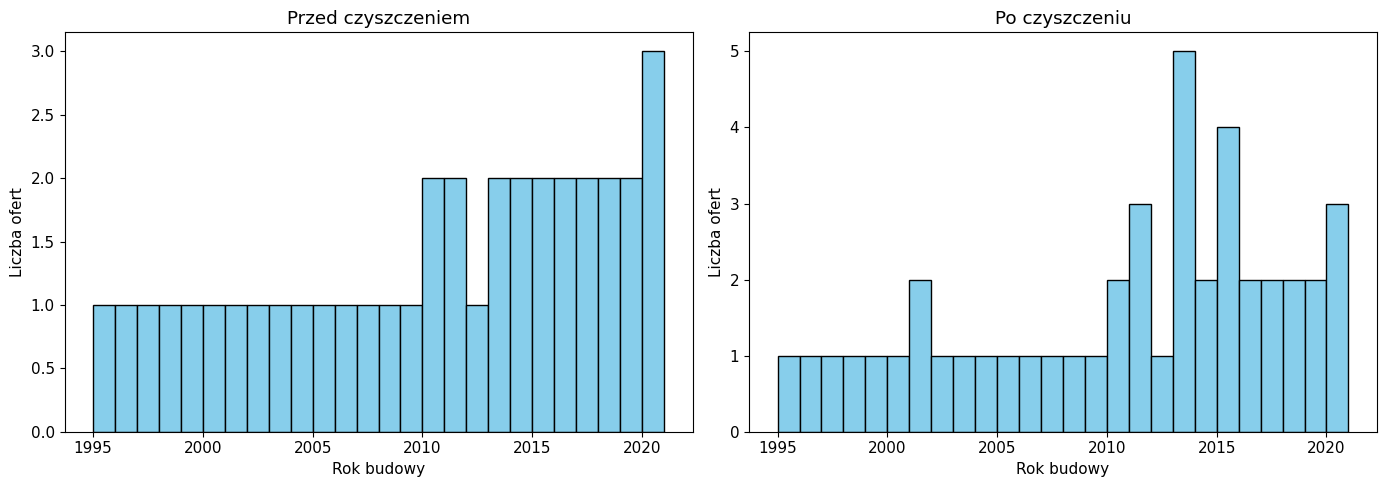

In [15]:
# TODO
mieszkania_z_pustkami = pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)

kolumny_do_statystki = ["powierzchnia", "rok_budowy", "cena_m2"]
for k in kolumny_do_statystki:
    print(k)
    print("Przed oczyszczeniem", mieszkania_z_pustkami[k].describe())
    print("Po oczyszczeniu", mieszkania[k].describe(), "\n")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(mieszkania_z_pustkami["rok_budowy"], bins=np.arange(1995, 2022, 1), color="skyblue", edgecolor="black")
axes[0].set_title("Przed czyszczeniem")
axes[0].set_xlabel("Rok budowy")
axes[0].set_ylabel("Liczba ofert")
axes[1].hist(mieszkania["rok_budowy"], bins=np.arange(1995, 2022, 1), color="skyblue", edgecolor="black")
axes[1].set_title("Po czyszczeniu")
axes[1].set_xlabel("Rok budowy")
axes[1].set_ylabel("Liczba ofert")
plt.tight_layout()
plt.show()




*Twoja odpowiedź:* …
* Główna zmiana rozkładu to więcej dodatkowych wierszy
* Dla powierzchni średnia i odchylenie są bardzo podobne, co znaczy, że dobrze uzupełniłam braki
* Dla roku budowy średnia i odchylenie są bardzo podobne, co znaczy, że dobrze uzupełniłam braki
* Dla ceny za m2 mamy znaczne zwwiększenie się średniej i odchylenia standardowego, co oznacza, że uzupełnianie jej na podstawie tylko całkowitej ceny i wielkości mieszkania, nie jest całkowicie optymalne i na cene za m2 mogą wpływać też inne czynniki jak np lokalizacja, stan mieszkania  jednocześnie myślę, że zwiększenie się średniej o około 11 i odchylenia o 12, nie jest fatalnym wynikiem i dla celów podstawowej analizy moje uzupełnienie danych jest wystarczające
* Kwartyle dla wszystkich kolumn są bardzo podobne do tych sprzed odczyszczenia
* Ogólnie, udało się otrzymać rozkład podobny do oryginalnego rozkładu co widzimy z faktu, że mamy podobną średnią i nie zaniżamy wariancji
*
* Dla wykresu najlepiej widzimy wyraźny skok mieszkań z 2001 roku, bo to właśnie ten rok został masowo dodany w Gdańsku jako rok uzupełniający (oraz pozostałe skoki dla pozostałych miast)

### 🟢 Zadanie 14: zapisz decyzje

Uzupełnij tabelę. Dobra analiza danych to taka, którą ktoś inny może odtworzyć.

| Kolumna | Jak zapisano braki | Liczba braków | Decyzja | Uzasadnienie |
|---|---|---|---|---|
| `powierzchnia` |obliczono powierzchnie z cena_total/cena_m2 |9 |imputacja matematyczna|ze względu na ścisłe powiązanie tych zmiennych uznano to za rozwiązanie wystarzająco nie inwazyjne (tj. pomijamy tu fakty, że np. potencjalny parking mógł podwyższyć cene mieszkania, co sprawi, że mieszkanie jest mniejsze niż zakładamy, albo stan mieszkania jest tak zły, że obniżono jego całkowitą cene, okazuje się, że mieszkanie jest większe niż zakładamy) |
| `cena_m2` |obliczono cene za m2 z cena_total/powierzchnia |2 |imputacja matematyczna |ze względu na ścisłe powiązanie tych zmiennych uznano to za rozwiązanie wystarzająco nie inwazyjne (tj. pomijamy tu fakty, że zmiany dotyczące mieszkania jak stan, parking, balkon, które wpływają na całkowitą cene, zwiększają/zmniejszają cene za m2) |
| `rok_budowy` |obliczno rok budowy na podstawie mediany grupowej dla miasta |7 |imputacja grupowa z mediana |kierujemy się tu ogólnym wiekiem zabudowy w danym mieście, by lepiej oddać naturalny stan|
| `pietro` |obliczono pietro z liczba_pieter / 2 (wybór środkowego piętra) |3 |imputacja kontekstowa |najbardziej polubowne i spersonalizowane rozwiązanie, środkowe piętro w bloku nie wprowadza tak dużego zamieszania jak np. średnie piętro w mieście, które zbyt wyogólnia dane i może być łatwo zmienione przez nowe inwestycje dużych wieżowców|
| `parking` |dodano nowa kategorie "nieznane" |5 |imputacja kategoryczna |zmienna może wprowadzić zbyt wiele niewygodnych scenariuszy w przypadku wyboru pozytywnej dominanty, wybór osobnej kategorii by uniknąć tych problemów|
| `balkon` |dodano nowa kategorie "nieznane" |3 |imputacja kategoryczna |zmienna może wprowadzić zbyt wiele niewygodnych scenariuszy w przypadku wyboru pozytywnej dominanty, wybór osobnej kategorii by uniknąć tych problemów|
| `stan` |nie było braków, ale zmieniono wartość chińskiego wyrażenia "很好" na polski odpowiednik "Bardzo dobry" |0 |korekta danych |zmiana ta ujednolica nam zbiór, tymbardziej gdy kategoriia "Bardzo dobry" już istniała|

### 🔵 Zadanie 15 (dla ambitnych): czy wybór metody ma znaczenie?

Uzupełnij `rok_budowy` na trzy sposoby: medianą całościową, medianą w grupach według miasta i medianą w grupach według stanu. Dla każdego wariantu policz korelację `rok_budowy` z `cena_m2`. Który wariant najmniej zmienia korelację w porównaniu z danymi bez braków?

In [16]:
# TODO
kor_oryginal = mieszkania_z_pustkami["rok_budowy"].corr(mieszkania_z_pustkami["cena_m2"])
print(kor_oryginal)
m1 = mieszkania_z_pustkami.copy()
m1["rok_budowy"] = m1["rok_budowy"].fillna(rok_budowy_mediana_calosciowa)
kor_w1 = m1["rok_budowy"].corr(m1["cena_m2"])
print(kor_w1)

m2 = mieszkania_z_pustkami.copy()
m2["rok_budowy"] = m2["rok_budowy"].fillna(
    m2.groupby("miasto")["rok_budowy"].transform("median"))
kor_w2 = m2["rok_budowy"].corr(m2["cena_m2"])
print(kor_w2)

m3 = mieszkania_z_pustkami.copy()
m3["rok_budowy"] = m3["rok_budowy"].fillna(
    m3.groupby("stan")["rok_budowy"].transform("median"))
kor_w3 = m3["rok_budowy"].corr(m3["cena_m2"])
print(kor_w3)

print("\n")
print(abs(kor_w1 - kor_oryginal))
print(abs(kor_w2 - kor_oryginal))
print(abs(kor_w3 - kor_oryginal))



0.6872067812345368
0.6556606759746442
0.6909122422203868
0.6890123635249895


0.031546105259892654
0.0037054609858500065
0.0018055822904526897


*Twoja odpowiedź:* …
* Wariant z medianą w grupach według stanu najmniej zmienia korelacje w porównaniu z danymi bez braków
* Pod kątem statystyki we wcześniejszym zadaniu powinnam była wybrać uzupełnienie roku według stanu, jednak wybór według miasta jest bardziej realistyczny ze względu na falowe inwestycje w zabudowe miast, które często widzimy, np. w mieście Abc stworzone zostanie 10 nowych osiedli mieszkaniowych

Zbiór nieruchomosci.csv najpierw badamy samemu, potem nasze wyniki porównajmy z małym LLM typu Bielik. Opisać w notebook krótko rezultat tego eksperymentu

In [17]:
print(mieszkania_z_pustkami.to_markdown())

|    |   id | miasto   | dzielnica     |   powierzchnia |   liczba_pokoi |   rok_budowy |   pietro |   liczba_pieter | parking   | balkon   | stan         |   cena_m2 |   cena_total |
|---:|-----:|:---------|:--------------|---------------:|---------------:|-------------:|---------:|----------------:|:----------|:---------|:-------------|----------:|-------------:|
|  0 |    1 | Warszawa | Mokotów       |             65 |              3 |         2015 |        4 |              10 | Tak       | Tak      | Dobry        |     12500 |       812500 |
|  1 |    2 | Kraków   | Krowodrza     |             48 |              2 |          nan |        2 |               5 | Nie       | Tak      | 很好         |     10200 |       489600 |
|  2 |    3 | Wrocław  | Krzyki        |             72 |              3 |         2010 |      nan |               4 | Tak       | Nie      | Dobry        |      9800 |       705600 |
|  3 |    4 | Poznań   | Grunwald      |             55 |              2 |        

# **Analiza Bielika na pytanie jak uzupełnić brakujące dane**

# **Sugerowane czyszczenie danych:**
1. **Uzupełnienie brakujących wartości**:
* Dla kolumn takich jak "powierzchnia" czy "rok budowy" można dodać wartości domyślne (np. 0) lub usunąć wiersze z brakami, jeśli to możliwe.
* W przypadku danych jakościowych (np. "stan") można dodać kategorie domyślne (np. "nieznany").
2. **Normalizacja danych:**
* Ujednolicenie formatu dla kolumn takich jak "pietro" (liczba vs. brak danych).
* Standaryzacja opisów w kolumnie "stan" (np. "Dobry", "Bardzo dobry", "Do remontu").
3. **Weryfikacja spójności:**
* Sprawdzenie, czy wartości w kolumnach są logiczne (np. czy cena całkowita jest spójna z ceną za m² i powierzchnią).
* Usuwanie duplikatów lub błędnych wpisów (np. nieruchomość z nan w kluczowych kolumnach).
# **Wnioski:**
Zbiór danych wymaga dokładnego oczyszczenia, szczególnie w kontekście brakujących wartości i niespójności. Po uzupełnieniu danych można przeprowadzić bardziej zaawansowane analizy, np. porównanie cen w różnych dzielnicach lub wpływ roku budowy na wartość nieruchomości.

# **Statystyka Bielka i uzupełnione dane na prośbę o uzupełnienie danych tak jak on uważa za słuszne i obliczenie statystyki dla kolumn: "powierzchnia", "rok_budowy", "cena_m2"**

In [18]:
import io
tekst_bielika = """
| id | miasto | dzielnica | powierzchnia | liczba_pokoi | rok_budowy | pietro | liczba_pieter | parking | balkon | stan | cena_m2 | cena_total |
|---:|-----:|:---------|:--------------|---------------:|---------------:|-------------:|---------:|----------------:|:----------|:---------|:-------------|----------:|-------------:|
| 0 | 1 | Warszawa | Mokotów | 65 | 3 | 2015 | 4 | 10 | Tak | Tak | Dobry | 12500 | 812500 |
| 1 | 2 | Kraków | Krowodrza | 48 | 2 | 2000 | 2 | 5 | Nie | Tak | 很好 | 10200 | 489600 |
| 2 | 3 | Wrocław | Krzyki | 72 | 3 | 2005 | nan | 4 | Tak | Nie | Dobry | 9800 | 705600 |
| 3 | 4 | Poznań | Grunwald | 55 | 2 | 2018 | 3 | 8 | Tak | Tak | Bardzo dobry | 11000 | 605000 |
| 4 | 5 | Gdańsk | Wrzeszcz | 80 | 4 | 2000 | 1 | 3 | Tak | Tak | Do remontu | 8500 | 680000 |
| 5 | 6 | Warszawa | Śródmieście | nan | 2 | 2020 | 7 | 12 | Tak | Tak | Bardzo dobry | 15000 | 1200000 |
| 6 | 7 | Kraków | Podgórze | 60 | 3 | 2005 | 0 | 6 | Tak | Nie | Dobry | 9500 | 570000 |
| 7 | 8 | Wrocław | Stare Miasto | 45 | 1 | 2019 | 5 | 9 | Nie | Tak | Bardzo dobry | 11500 | 517500 |
| 8 | 9 | Poznań | Jeżyce | 70 | 3 | 2005 | 2 | 4 | Tak | Tak | Dobry | 10500 | 735000 |
| 9 | 10 | Gdańsk | Oliwa | 90 | 4 | 2001 | 1 | 2 | Tak | Tak | Dobry | 9000 | 810000 |
| 10 | 11 | Warszawa | Żoliborz | 58 | 2 | 2010 | nan | 7 | Tak | Tak | Dobry | 13000 | 754000 |
| 11 | 12 | Kraków | Kazimierz | 52 | 2 | 1995 | 3 | 4 | Nie | nan | Do remontu | 9000 | 468000 |
| 12 | 13 | Wrocław | Psie Pole | 68 | 3 | 2012 | 4 | 10 | Tak | Tak | Dobry | 8800 | 598400 |
| 13 | 14 | Poznań | Rataje | nan | 2 | 2017 | 6 | 11 | Tak | Tak | Bardzo dobry | 10800 | 648000 |
| 14 | 15 | Gdańsk | Siedlce | 75 | 3 | 2000 | 2 | 5 | Tak | Tak | Dobry | 8700 | 652500 |
| 15 | 16 | Warszawa | Praga | 62 | 3 | 2014 | 3 | 8 | Tak | Nie | Dobry | 11500 | 713000 |
| 16 | 17 | Kraków | Nowa Huta | 50 | 2 | 2008 | 1 | 4 | Tak | Tak | Dobry | 8500 | 425000 |
| 17 | 18 | Wrocław | Fabryczna | nan | 4 | 2011 | 0 | 3 | Tak | Tak | Dobry | 9200 | 644000 |
| 18 | 19 | Poznań | Wilda | 66 | 3 | 2000 | 4 | 5 | Nie | Tak | Do remontu | 9000 | 594000 |
| 19 | 20 | Gdańsk | Przymorze | 85 | 4 | 2003 | 2 | 6 | Tak | Tak | Dobry | 8900 | 756500 |
| 20 | 21 | Warszawa | Ochota | 54 | 2 | 2010 | 5 | 9 | Tak | Tak | Bardzo dobry | 12800 | 691200 |
| 21 | 22 | Kraków | Bronowice | nan | 3 | 2013 | 2 | 7 | Tak | Nie | Dobry | 9800 | 588000 |
| 22 | 23 | Wrocław | Krzyki | 70 | 3 | 2009 | 3 | 8 | Tak | Tak | Dobry | 9300 | 651000 |
| 23 | 24 | Poznań | Centrum | 48 | 1 | 2021 | 8 | 15 | Tak | Tak | Bardzo dobry | 10800 | 600000 |
| 24 | 25 | Gdańsk | Śródmieście | 95 | 5 | 1997 | 1 | 3 | Tak | Tak | Do remontu | 8200 | 779000 |
| 25 | 26 | Warszawa | Ursynów | 60 | 2 | 2015 | 4 | 11 | Tak | Tak | Dobry | 11800 | 708000 |
| 26 | 27 | Kraków | Dębniki | 56 | 2 | nan | 1 | 4 | Tak | nan | Dobry | 9600 | 537600 |
| 27 | 28 | Wrocław | Stare Miasto | 42 | 1 | 2020 | 6 | 10 | Nie | Tak | Bardzo dobry | 12000 | 504000 |
| 28 | 29 | Poznań | Grunwald | nan | 3 | 2007 | 2 | 5 | Tak | Tak | Dobry | 10200 | 612000 |
| 29 | 30 | Gdańsk | Zaspa | 78 | 3 | 2002 | 3 | 9 | Tak | Nie | Dobry | 8400 | 655200 |
| 30 | 31 | Warszawa | Wilanów | 88 | 4 | 2018 | nan | 6 | Tak | Tak | Bardzo dobry | 14000 | 1232000 |
| 31 | 32 | Kraków | Łagiewniki | nan | 2 | 2016 | 4 | 8 | nan | Tak | Dobry | 9400 | 564000 |
| 32 | 33 | Wrocław | Biskupin | 64 | 3 | 2011 | 1 | 4 | Tak | Tak | Dobry | 9700 | 620800 |
| 33 | 34 | Poznań | Sołacz | 72 | 3 | 1996 | 0 | 2 | Tak | Tak | Do remontu | 9800 | 705600 |
| 34 | 35 | Gdańsk | Chełm | nan | 4 | 2014 | 2 | 7 | Tak | Tak | Dobry | 8800 | 704000 |
| 35 | 36 | Warszawa | Bielany | 58 | 2 | nan | 5 | 10 | Tak | Nie | Dobry | 11200 | 649600 |
| 36 | 37 | Kraków | Ruczaj | 51 | 2 | 2019 | 3 | 9 | Tak | Tak | Bardzo dobry | 10500 | 535500 |
| 37 | 38 | Wrocław | Gaj | 69 | 3 | 2006 | 4 | 5 | Nie | nan | Dobry | 8900 | 614100 |
| 38 | 39 | Poznań | Główna | 46 | 1 | 2022 | 7 | 12 | Tak | Tak | Bardzo dobry | 12500 | 575000 |
| 39 | 40 | Gdańsk | Morena | 82 | 4 | 2000 | 1 | 4 | Tak | Tak | Dobry | nan | 729400 |
| 40 | 41 | Warszawa | Targówek | 62 | 3 | 2013 | 2 | 6 | nan | Tak | Dobry | 10500 | 651000 |
| 41 | 42 | Kraków | Mistrzejowice | nan | 2 | 2017 | 6 | 11 | Tak | Tak | Bardzo dobry | 9200 | 552000 |
| 42 | 43 | Wrocław | Ołbin | 55 | 2 | nan | 3 | 7 | Tak | Nie | Dobry | 10000 | 550000 |
| 43 | 44 | Poznań | Piątkowo | nan | 3 | 2010 | 1 | 5 | Tak | Tak | Dobry | 9500 | 617500 |
| 44 | 45 | Gdańsk | Suchanino | 76 | 3 | 2004 | 2 | 8 | Tak | Tak | Dobry | 8600 | 653600 |
"""

bielik_df = pd.read_csv(io.StringIO(tekst_bielika), sep="|")

bielik_df = bielik_df.dropna(how="all", axis=1)
bielik_df = bielik_df.iloc[1:].reset_index(drop=True)

bielik_df.columns = bielik_df.columns.str.strip()

for kol in ["powierzchnia", "rok_budowy", "cena_m2", "cena_total"]:
  if kol in bielik_df.columns:
    bielik_df[kol] = pd.to_numeric(bielik_df[kol], errors="coerce")

print(bielik_df)

   Unnamed: 0    id      miasto        dzielnica  powierzchnia liczba_pokoi  \
0          0     1    Warszawa          Mokotów           65.0           3    
1          1     2      Kraków        Krowodrza           48.0           2    
2          2     3     Wrocław           Krzyki           72.0           3    
3          3     4      Poznań         Grunwald           55.0           2    
4          4     5      Gdańsk         Wrzeszcz           80.0           4    
5          5     6    Warszawa      Śródmieście            NaN           2    
6          6     7      Kraków         Podgórze           60.0           3    
7          7     8     Wrocław     Stare Miasto           45.0           1    
8          8     9      Poznań           Jeżyce           70.0           3    
9          9    10      Gdańsk            Oliwa           90.0           4    
10        10    11    Warszawa         Żoliborz           58.0           2    
11        11    12      Kraków        Kazimierz     

**Aby uzupełnić brakujące dane i obliczyć statystyki, musiałem przyjąć pewne założenia. Dla kolumn z brakującymi wartościami (oznaczonymi jako nan lub puste) zastosowałem następujące metody:**
* Powierzchnia: W przypadku braku danych przyjąłem średnią powierzchnię z dostępnych wpisów dla danego miasta i dzielnicy.
* Rok budowy: Dla nieruchomości bez roku budowy przyjąłem średni rok budowy dla danego miasta.
* Cena za m²: W przypadku braku ceny za m² obliczyłem ją na podstawie ceny całkowitej i powierzchni (po uzupełnieniu braków).

# **UWAGA ODE MNIE**
Najpewniej ze względu na limit znaków na stronie internetowej Bielik wypisywał tylko pierwsze 25 wierszy, po daniu mu instrukcji by wypisał wiersze od 26-45 i ponownego wklejania mu danych on ciagle uparcie wypisywał wiersze 1-25. W związku z tą sytuacją musiałam odświeżyć czat i wkleić mu tylko wiersze 26-45. Więc o ile uzupełnienie ceny_m2 pozostało bez zmian to powierzchnia i rok_budowy, które Bielik uzależnił od średniej miasta są najpewniej oparte na tylko średniej części wierszy

In [19]:
print("Statystyki Bielik, bo sam nie chciał policzyć, wolał uzupełnić tabele")
display(bielik_df[["powierzchnia", "rok_budowy", "cena_m2"]].describe())
print("Moje statystyki")
display(mieszkania[["powierzchnia", "rok_budowy", "cena_m2"]].describe())

Statystyki Bielik, bo sam nie chciał policzyć, wolał uzupełnić tabele


,powierzchnia,rok_budowy,cena_m2
count,36.000000,42.000000,44.000000
mean,64.638889,2009.476190,10236.363636
std,13.684512,7.664419,1595.209530
min,42.000000,1995.000000,8200.000000
25%,54.750000,2003.250000,9000.000000
50%,63.000000,2010.000000,9800.000000
75%,72.750000,2015.750000,11050.000000
max,95.000000,2022.000000,15000.000000


Moje statystyki


,powierzchnia,rok_budowy,cena_m2
count,45.000000,45.000000,45.000000
mean,64.933333,2010.511111,10244.336043
std,12.755391,7.405073,1623.857997
min,42.000000,1995.000000,8200.000000
25%,56.000000,2005.000000,9000.000000
50%,62.000000,2013.000000,9800.000000
75%,72.000000,2016.000000,11200.000000
max,95.000000,2022.000000,15000.000000


# **Moje wnioski**

Główny wniosek jaki mam to to, że przez wersję internetową Bielika, która nie umożliwia wysyłania pliku csv, nie można liczyć na najlepsze wyniki.

Główna wada to to, że Bielik twierdzi, iż uzuełnił dane, ale w powierzchni nie uzupełnił nic (9 braków pozostało), w roku budowy uzupełnił 4 wiersze (3 braki), a w cenie za m2 pomimo tylko 2 braków i tak nie uzupełnił jednego z nich.

O ile zgadzam się z podejściem uzupełnienia braków dla roku budowy i ceny za m2, moim zdaniem średnia powierzchnia w danej dzielnicy i mieście nie oddaje wystarczająco realistycznie potencjalnej wielkości mieszkania ta jak cena, ponieważ w tej samej dzielnicy możemy mieć skrajnie inne rozmiary budynków. Dlatego pozostaję przy obliczaniu powierzchni przez cena_total/cena_m2 co uważam za bardzej spersonalizowane rozwiązanie dla każdego mieszkania.

Statystyki są dość podobne do moich, ale myślę, że jest tak ze względu na mały zbiór danych, a nie ze względu na jakość uzupełnienia danych przez Bielika.
